In [1]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from pathlib import Path
import umap

import numpy as np
import torch

from representation_models import ConvAutoencoder
from dataloading_demo import get_full_dataloader, get_splits_dataloaders

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
weights_path = Path("models_weights/conv_autoencoder.pth")

model = ConvAutoencoder().to(device)
model.load_state_dict(
    torch.load(weights_path, map_location=device, weights_only=True)
)
model.eval()

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Flatten(start_dim=1, end_dim=-1)
    (13): Linear(in_features=32768, out_features=128, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=128, out_features=32768, bias=True)
    (1)

In [4]:
train_dl, val_dl, test_dl = get_splits_dataloaders(shuffle_train=False)
_, full_dl = get_full_dataloader()

In [5]:
@torch.inference_mode()
def encode_loader(model, loader):
    print("Encoding...")
    model.eval()
    feats = []
    for batch in tqdm(loader):
        z = model.encode(batch["image"].to(device, non_blocking=True))
        feats.append(z.cpu())
    return torch.cat(feats).numpy()

In [6]:
full_encoded = encode_loader(model, full_dl)
train_encoded = encode_loader(model, train_dl)
val_encoded = encode_loader(model, val_dl)
test_encoded = encode_loader(model, test_dl)

Encoding...


  0%|          | 0/1608 [00:00<?, ?it/s]

Encoding...


  0%|          | 0/1287 [00:00<?, ?it/s]

Encoding...


  0%|          | 0/161 [00:00<?, ?it/s]

Encoding...


  0%|          | 0/161 [00:00<?, ?it/s]

In [7]:
print(train_encoded.shape)  # expected: (number_of_images, 128)

# Fit scaling only on training data, then apply it to every split.
scaler = StandardScaler()
X_train = scaler.fit_transform(train_encoded)
X_val = scaler.transform(val_encoded)
X_test = scaler.transform(test_encoded)

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)

train_labels = kmeans.fit_predict(X_train)
val_labels = kmeans.predict(X_val)
test_labels = kmeans.predict(X_test)

(82321, 128)


c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


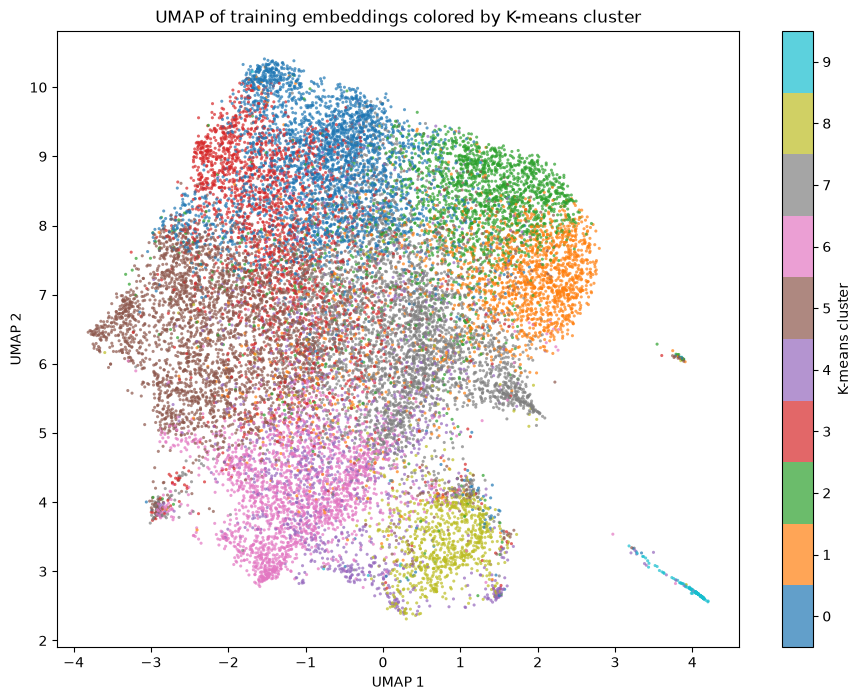

In [ ]:
# UMAP is for visualization only; K-means was fitted in the original 128-D space.
# Use a reproducible subset to keep the 2-D projection manageable.
max_points = 20000
rng = np.random.default_rng(42)
if len(X_train) > max_points:
    plot_indices = np.sort(rng.choice(len(X_train), size=max_points, replace=False))
else:
    plot_indices = np.arange(len(X_train))

X_plot = X_train[plot_indices]
labels_plot = train_labels[plot_indices]

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
)
embedding_2d = reducer.fit_transform(X_plot)

fig, ax = plt.subplots(figsize=(11, 8))
points = ax.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    c=labels_plot,
    cmap="tab10",
    vmin=-0.5,
    vmax=kmeans.n_clusters - 0.5,
    s=5,
    alpha=0.7,
    linewidths=0,
)
fig.colorbar(points, ax=ax, ticks=np.arange(kmeans.n_clusters), label="K-means cluster")
ax.set(title="UMAP of training embeddings colored by K-means cluster", xlabel="UMAP 1", ylabel="UMAP 2")
plt.show()